**Imports** Run the model from t=0 upto t=20 by using different beta values

In [3]:
!py simulate_abm.py --num-infected 1 --num-steps 15 --gamma 10 \
  --beta-start 0.0 --beta-step 0.05 --beta-count 20 \
  --tau 0 --runs 20 --out abm_bank_all_15_test.npz 

Simulated agent spread by using an ABM,
Visualized infection states on a grid, 
Calculated  distances of the infected agents from the center,
plotted the distance distribution.

**Difference in the number of infected in simulated and obs**

Estimates β by comparing the simulated number of infected agents at step 20 with the observed infected from the CSV, selecting the β with the smallest difference. 

Compares simulated and observed radious distance distributions of infected agents from the grid center for different β values.

Runs simulations for each β and plots histograms of infected distances.

Plots the observed distance distribution from CSV data.

Computes the difference between simulated and observed distributions to estimate the β with the closest match.

Combine all beta estimations methods in line plots

Plotting by using the new particle_filter.p file 

In [2]:
import os
import numpy as np
from particle_filter_abm_c_dist import (
    run_simulations,
    plot_half,
    get_all_simulations,
    plot_all_runs, 
    plot_mean_betas,
    plot_all_vs_half,
    plot_mean_betas,
    export_mean_betas_to_csv
)



t_start = 15
t_final = 420
window  = 15

simulation_data = f"abm_bank_all_15.npz"
obs = "gent_data.csv"


os.makedirs(f"figsc_{window}", exist_ok=True)


#run_simulations(
#    observed_csv=obs,
#    bank_path=simulation_data,
#    t_start=t_start, t_final=t_final, window=window,
#    run_replicates=2, gamma=10,
#    append_back_to_bank=True,
#    beta_start=0.0,
#    beta_step=0.05,
#    beta_count=20,
#)



beta_xlim  = (0.0, 1.01)
beta_xtick = np.arange(0.0, 1.001, 0.1)

#for t in range(t_start, t_final + 1, window):
    
#    plot_half(
#        simulation_data,
#        t=t,
#        title=f"Lower half at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figc/lower_half_t{t}.pdf",
#        show=False,
#        close=True
#    )    

#for t in range(t_start + window, t_final + 1, window):
#    
#    bC_all, dC_all = get_all_simulations(simulation_data, t=t)
#    plot_all_runs(
#        betas_C=bC_all, dC=dC_all,
#        title=f"All runs at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figc/all_runs_t{t}.pdf",
#        show=False,
#        close=True
#    )


time_xlim  = (0, t_final+window)
time_xtick = np.arange(0, t_final+1,  3 * window) 


for t in range(t_start + window, t_final + 1, window):
    plot_all_vs_half(
        bank_path=simulation_data,
        t=t,
        title=f"All runs at t={t}",
        xlim=beta_xlim,
        xtick=beta_xtick,
        save_path=f"figsc_{window}/all_vs_half_t{t}.png",
        show=False,
        close=True,
    )


plot_mean_betas(
    bank_path=simulation_data,
    title=f'Rolling window = {window}',
    overlay_csv_path="gent_data.csv",         
    save_path=f"figsc_{window}/ABL.png",
    xlim=time_xlim,
    ylim=beta_xlim, 
    xtick=time_xtick,
    ytick=beta_xtick,
    show=True,
    close=True
)


export_mean_betas_to_csv(
    bank_path=simulation_data,
    out_csv=f"estimated_beta_ABL_{window}.csv",
)


In [20]:
!py particle_filter_abm_c_dist_inf_plot.py \
  --bank-path abm_bank_all_15.npz \
  --t-max 540 \
  --mode over_time \
  --observed-csv gent_data.csv \
  --save figsc_10/selected_infected_10.png \
  --title "Observed infected and particle filter simulated infected over time" 


In [ ]:
!py -m pip install pandas

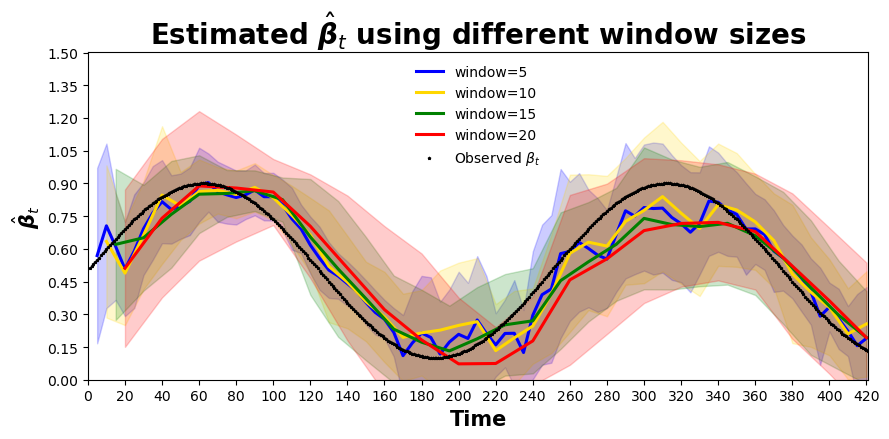

In [1]:
import numpy as np
from Beta_plots import plot_mean_betas_multi

t_final = 420


WINDOWS = [5, 10, 15, 20]

BANKS = {
    5:  "abm_bank_all_5.npz",
    10: "abm_bank_all_10.npz",
    15: "abm_bank_all_15.npz",
    20: "abm_bank_all_20.npz",
}

COLORS = {
    5:  "blue",
    10: "gold",
    15: "green",
    20: "red",
}

SELECT = [5,10,15,20]        

plot_mean_betas_multi(
    bank_paths=[BANKS[w] for w in SELECT],
    labels=[f"window={w}" for w in SELECT],
    observed_csv_path="gent_data.csv",
    save_path="figs_multi/ABL_estimated_beta.png",
    xlim=(0, t_final+1),
    xtick=np.arange(0, t_final+1, 20),
    ylim=(0.0, 1.501),
    ytick=np.arange(0.0, 1.501, 0.15),
    line_colors=[COLORS[w] for w in SELECT],
    line_alphas=[1.0 for _ in SELECT],
    ci_colors=[COLORS[w] for w in SELECT],
    ci_alphas=[0.20 for _ in SELECT],
    observed_marker="*",
    observed_size=3,
)

In [1]:

import numpy as np
from Beta_plots import plot_posterior_at_time

plot_posterior_at_time(
    bank_path="abm_bank_all_20.npz",
    time_point=60,
    observed_csv_path="gent_data.csv",
    save_path="figs/posterior_t1360_20.pdf"
)


In [3]:
from infected_dist_plot import plot_infected_with_previous_weights, plot_infected_posterior_at_time

plot_infected_with_previous_weights(
    bank_path="abm_bank_all_20.npz",
    time_point=60
)


plot_infected_posterior_at_time(
    bank_path="abm_bank_all_20.npz",
    time_point=60
)

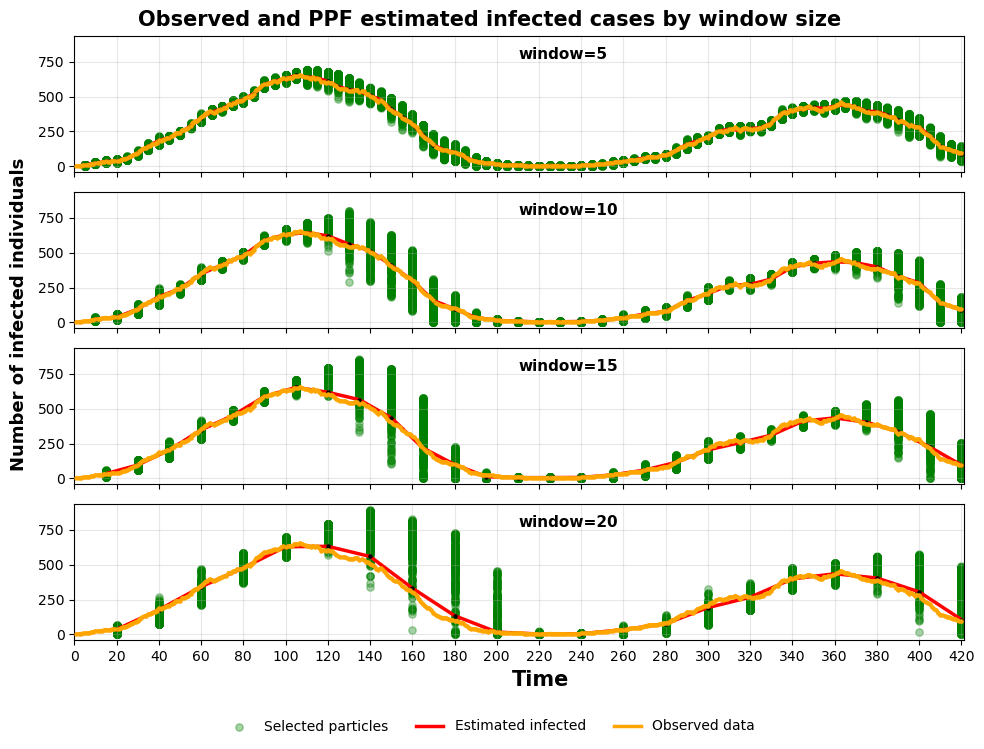

In [1]:
import numpy as np
from infected_plot import plot_selected_infected_multi_subplots

t_final = 420

plot_selected_infected_multi_subplots(
    bank_paths=[
        "abm_bank_all_5.npz",
        "abm_bank_all_10.npz",
        "abm_bank_all_15.npz",
        "abm_bank_all_20.npz",
    ],
    labels=["window=5", "window=10", "window=15", "window=20"],
    observed_csv_path="gent_data.csv",
    save_path="figs_multi/infected_windows_subplots_ABL.png",
    xlim=(0, t_final+1),
    xtick=np.arange(0, t_final + 1, 20),
    ylim=None,    
    ytick=None,    
    t_max=420,
    show=True,
    close=True,
)


In [2]:
!py window_error.py sweep \
  --banks "5=abm_bank_all_5.npz,10=abm_bank_all_10.npz,15=abm_bank_all_15.npz, 20=abm_bank_all_20.npz"\
  --observed-csv gent_data.csv \
  --t-max 420\
  --metrics-path window_metrics_ABL.npz

error
error
error
error
Metrics file: window_metrics_ABL.npz


In [1]:
!py window_error.py box --metrics-path window_metrics_ABL.npz  --save-fig

In [1]:
from make_pf_video_infected import make_pf_video_beta_vs_infected

make_pf_video_beta_vs_infected(
    bank_path="abm_bank_all_5.npz",
    observed_csv="gent_data.csv",   
    out_path="Estimated_beta_Infected_videos_distance_ABL.gif",
    fps=3,
)

'Estimated_beta_Infected_videos_distance_ABL.gif'

Use this one

In [1]:
!py particles_infected.py --bank-path abm_bank_all_10_pf_results.npz  --observed-csv gent_data.csv  --t-end 320 --window 10 --nrows 3 --ncols 5 --save figs/particles_infected_beta_ABL.png


[OK] Saved: figs/particles_infected_beta_ABL.png


In [2]:
!py particle_filter_abm_c_dist_inf_plot.py --bank-path abm_bank_all_5_pf_results.npz --observed-csv gent_data.csv --t-print 420